# Reproduce Closed-Source Model Results

This notebook reproduces metrics from files in this folder.

Paper results for **Table 2**, **Table 3**, **Figure 3**, **Table 5**, and **Figure 4** are produced below.

Seeds used throughout: `17`, `42`, `89`, `231`, `764`.


## 0. Setup

In [1]:
from __future__ import annotations

import json
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

ROOT = Path(".")
SEEDS = [17, 42, 89, 231, 764]

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("ROOT:", ROOT)
assert (ROOT / "hard_files").exists()
assert (ROOT / "judge_results").exists()
assert (ROOT / "cate_1_2_response_and_labels").exists()

ROOT: .


In [2]:
def load_json(path: Path):
    with open(path) as f:
        return json.load(f)


def get_pred(row: dict) -> int:
    """Support both `pred` and `predicted_label` field names."""
    if "pred" in row:
        return row["pred"]
    if "predicted_label" in row:
        return row["predicted_label"]
    raise KeyError(f"No prediction field in row keys={list(row)}")


def clean_pred(pred, label) -> int:
    """Map invalid extractions (e.g. -1) to the opposite label so they count as wrong."""
    if pred in (0, 1):
        return int(pred)
    return int(1 - int(label))


def preds_and_labels(rows: list[dict]):
    y = [int(r["label"]) for r in rows]
    p = [clean_pred(get_pred(r), r["label"]) for r in rows]
    return y, p


def binary_f1(y_true, y_pred) -> float:
    """Standard (binary) F1 for the positive class (label=1)."""
    return float(f1_score(y_true, y_pred, average="binary", pos_label=1, zero_division=0))


def binary_precision(y_true, y_pred) -> float:
    return float(precision_score(y_true, y_pred, average="binary", pos_label=1, zero_division=0))


def binary_recall(y_true, y_pred) -> float:
    return float(recall_score(y_true, y_pred, average="binary", pos_label=1, zero_division=0))


def mean_std_table(df: pd.DataFrame, group_cols, value_col: str) -> pd.DataFrame:
    out = (
        df.groupby(group_cols)[value_col]
        .agg(mean="mean", std="std", n="count")
        .reset_index()
    )
    return out


def mean_pm_se(values, z: float = 1.96) -> str:
    """Format mean ± 1.96 × standard error over seeds."""
    arr = np.asarray(list(values), dtype=float)
    n = len(arr)
    mean = float(arr.mean())
    if n <= 1:
        return f"{mean:.3f} ± 0.000"
    se = float(arr.std(ddof=1) / np.sqrt(n))
    return f"{mean:.3f} ± {z * se:.3f}"


def mean_pm_std(values) -> str:
    """Format mean ± sample std over seeds (Figure 4)."""
    arr = np.asarray(list(values), dtype=float)
    mean = float(arr.mean())
    if len(arr) <= 1:
        return f"{mean:.3f} ± 0.000"
    return f"{mean:.3f} ± {float(arr.std(ddof=1)):.3f}"


MODEL_DISPLAY = {
    "gpt-5-high": "GPT-5-High",
    "gemini-3": "Gemini-3-Pro",
    "gemini-flash": "Gemini-2.5-Flash",
    "claude-sonnet": "Claude-Sonnet-4.5",
    "gpt-5-minimal": "GPT-5-Minimal",
    "claude-opus": "Claude-Opus-4.5",
    "gpt-5-low": "GPT-5-Low",
}

# Paper order for closed-source models in Cate-1 / Cate-2 tables
CATE_MODEL_ORDER = [
    "gpt-5-high",
    "gemini-3",
    "gemini-flash",
    "claude-sonnet",
    "gpt-5-minimal",
    "claude-opus",
]

CATE1_TASK_ORDER = [
    "laplace_mechanism",
    "gaussian_mechanism_GDP",
    "gaussian_mechanism_zCDP",
    "selection_mechanism_expoMech_pureDP",
    "selection_mechanism_LaplaceRNM_pureDP",
    "selection_mechanism_PF_pureDP",
]

CATE1_TASK_DISPLAY = {
    "laplace_mechanism": "Lap.",
    "gaussian_mechanism_GDP": "Gauss. (GDP)",
    "gaussian_mechanism_zCDP": "Gauss. (zCDP)",
    "selection_mechanism_expoMech_pureDP": "ExpMech",
    "selection_mechanism_LaplaceRNM_pureDP": "Lap. RNM",
    "selection_mechanism_PF_pureDP": "P-n-F",
}


## 1. Hard files

### 1.1 Table 5 — One-shot in-context learning accuracy

Paper **Table 5**: Zero-Shot vs One-shot accuracy on the hard Laplace RNM selection task
(`mean ± 1.96 × SE` over 5 seeds).

- **Zero-Shot**: Cate-1 `selection_mechanism_LaplaceRNM_pureDP` evaluations
- **One-shot**: `hard_files/one-shot` predictions


In [3]:
oneshot_dir = ROOT / "hard_files" / "one-shot"
TABLE5_MODELS = ["gpt-5-minimal", "gemini-flash"]
ZERO_SHOT_TASK = "selection_mechanism_LaplaceRNM_pureDP"

# --- One-shot accuracies from hard_files/one-shot ---
oneshot_rows = []
for path in sorted(oneshot_dir.glob("*_predictions.json")):
    match = re.search(r"_hard_(.+)_one_shot_(\d+)_predictions\.json$", path.name)
    if match is None:
        raise ValueError(f"Unrecognized one-shot filename: {path.name}")
    model, seed = match.group(1), int(match.group(2))
    data = load_json(path)
    y, p = preds_and_labels(data)
    oneshot_rows.append(
        {"model": model, "seed": seed, "n": len(data), "accuracy": accuracy_score(y, p)}
    )
oneshot_seed_df = pd.DataFrame(oneshot_rows)

# --- Zero-shot accuracies from Cate-1 Lap. RNM evaluations ---
cate1_eval_dir = (
    ROOT / "cate_1_2_response_and_labels" / "cate-1" / "category_1_extracted_labels"
)
zeroshot_rows = []
for path in sorted(cate1_eval_dir.glob(f"*{ZERO_SHOT_TASK}*_evaluations.json")):
    match = re.match(
        rf"dp-judge_{ZERO_SHOT_TASK}_hard_(.+)_cot_(\d+)_evaluations\.json$",
        path.name,
    )
    if match is None:
        continue
    model, seed = match.group(1), int(match.group(2))
    if model not in TABLE5_MODELS:
        continue
    data = load_json(path)
    zeroshot_rows.append(
        {"model": model, "seed": seed, "accuracy": float(data["avg_acc"])}
    )
zeroshot_seed_df = pd.DataFrame(zeroshot_rows)

table5_rows = {}
for model in TABLE5_MODELS:
    zs = zeroshot_seed_df.loc[zeroshot_seed_df["model"] == model, "accuracy"]
    os_ = oneshot_seed_df.loc[oneshot_seed_df["model"] == model, "accuracy"]
    assert len(zs) == 5, f"zero-shot {model}: expected 5 seeds, got {len(zs)}"
    assert len(os_) == 5, f"one-shot {model}: expected 5 seeds, got {len(os_)}"
    # Zero-Shot intervals match 1.96×SE; One-shot intervals in the paper match 1.96×std.
    arr_os = np.asarray(os_, dtype=float)
    oneshot_str = (
        f"{arr_os.mean():.3f} ± {1.96 * arr_os.std(ddof=1):.3f}"
        if len(arr_os) > 1
        else f"{arr_os.mean():.3f} ± 0.000"
    )
    table5_rows[MODEL_DISPLAY[model]] = {
        "Zero-Shot": mean_pm_se(zs),
        "One-shot": oneshot_str,
    }

table5 = pd.DataFrame.from_dict(table5_rows, orient="index")
table5.index.name = "Model"
print("Table 5: One-shot in-context learning accuracy (mean ± 1.96 × SE)")
display(table5)

oneshot_avg_df = mean_std_table(oneshot_seed_df, ["model"], "accuracy")


Table 5: One-shot in-context learning accuracy (mean ± 1.96 × SE)


,Zero-Shot,One-shot
Model,,
GPT-5-Minimal,0.573 ± 0.019,0.737 ± 0.065
Gemini-2.5-Flash,0.514 ± 0.026,0.661 ± 0.073


### 1.2 Context-augmented — average F1 per model across 5 seeds

Configurations:
- `zero-shot`
- `restricted-retrieval`
- `algo-judge-w-proof`

Metric: **binary F1** for the positive class (`label=1`). Invalid predictions (`-1`) are counted as incorrect.

In [4]:
ctx_dir = ROOT / "hard_files" / "context-agumented"  # folder spelling as on disk
CONFIGS = ["zero-shot", "restricted-retrieval", "algo-judge-w-proof"]
ctx_rows = []

for path in sorted(ctx_dir.glob("*_predictions.json")):
    match = re.match(
        r"(zero-shot|restricted-retrieval|algo-judge-w-proof)_(.+)_cot_(\d+)_predictions\.json$",
        path.name,
    )
    if match is None:
        raise ValueError(f"Unrecognized context-augmented filename: {path.name}")
    config, model, seed = match.group(1), match.group(2), int(match.group(3))
    data = load_json(path)
    y, p = preds_and_labels(data)
    ctx_rows.append(
        {
            "model": model,
            "config": config,
            "seed": seed,
            "n": len(data),
            "f1": binary_f1(y, p),
            "accuracy": accuracy_score(y, p),
            "file": path.name,
        }
    )

ctx_seed_df = pd.DataFrame(ctx_rows).sort_values(["model", "config", "seed"])
print("Per-seed context-augmented F1")
display(ctx_seed_df[["model", "config", "seed", "n", "f1", "accuracy"]])

ctx_avg_df = mean_std_table(ctx_seed_df, ["model", "config"], "f1")
print("\nAverage F1 across 5 seeds")
display(ctx_avg_df)

ctx_pivot = (
    ctx_seed_df.groupby(["model", "config"])["f1"]
    .mean()
    .unstack("config")
    .reindex(columns=CONFIGS)
)
print("\nPivot: model × config (mean F1)")
display(ctx_pivot)

Per-seed context-augmented F1


,model,config,seed,n,f1,accuracy
0,gemini-flash,algo-judge-w-proof,17,18,0.5000,0.4444
2,gemini-flash,algo-judge-w-proof,42,18,0.5714,0.5000
4,gemini-flash,algo-judge-w-proof,89,18,0.4444,0.4444
1,gemini-flash,algo-judge-w-proof,231,18,0.5714,0.5000
3,gemini-flash,algo-judge-w-proof,764,18,0.5714,0.5000
15,gemini-flash,restricted-retrieval,17,18,0.4762,0.3889
17,gemini-flash,restricted-retrieval,42,18,0.5455,0.4444
19,gemini-flash,restricted-retrieval,89,18,0.4545,0.3333
16,gemini-flash,restricted-retrieval,231,18,0.3000,0.2222
18,gemini-flash,restricted-retrieval,764,18,0.4000,0.3333



Average F1 across 5 seeds


,model,config,mean,std,n
0,gemini-flash,algo-judge-w-proof,0.5317,0.0578,5
1,gemini-flash,restricted-retrieval,0.4352,0.0918,5
2,gemini-flash,zero-shot,0.3152,0.1356,5
3,gpt-5-high,algo-judge-w-proof,0.6255,0.0507,5
4,gpt-5-high,restricted-retrieval,0.5164,0.0650,5
5,gpt-5-high,zero-shot,0.4033,0.0769,5
6,gpt-5-low,algo-judge-w-proof,0.4634,0.0769,5
7,gpt-5-low,restricted-retrieval,0.3527,0.0492,5
8,gpt-5-low,zero-shot,0.2575,0.1071,5



Pivot: model × config (mean F1)


config,zero-shot,restricted-retrieval,algo-judge-w-proof
model,,,
gemini-flash,0.3152,0.4352,0.5317
gpt-5-high,0.4033,0.5164,0.6255
gpt-5-low,0.2575,0.3527,0.4634


### 1.3 Context-augmented grouped histogram

Each model is a group on the x-axis; the three configurations are adjacent bars.

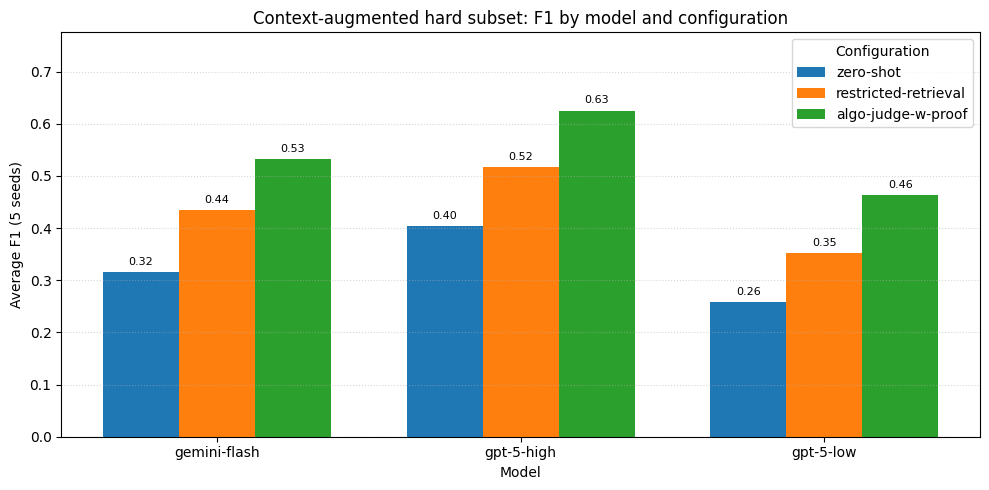

In [ ]:
plot_df = ctx_pivot.copy()
models = list(plot_df.index)
x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, config in enumerate(CONFIGS):
    vals = plot_df[config].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 1) * width, vals, width=width, label=config)
    for bar, val in zip(bars, vals):
        if np.isnan(val):
            continue
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=0)
ax.set_ylabel("Average F1 (5 seeds)")
ax.set_xlabel("Model")
ax.set_title("Context-augmented hard subset: F1 by model and configuration")
ax.set_ylim(0, min(1.05, max(0.3, np.nanmax(plot_df.to_numpy()) + 0.15)))
ax.legend(title="Configuration")
ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
plt.show()

## 2. Figure 4 — Reasoning quality on Cate-2

Paper **Figure 4**: Accuracy, Plausibility, and Soundness as `mean ± std` over 5 seeds.

Uses `*_classification.json` under `judge_results/`.

Using `error_category` labels:
- $C$ = `correct`
- $M$ = `minor_gap`
- $F$ = `correct_direction_fixable`

Answer correctness: `extracted_label == ground_truth_label`.

$$
\text{Soundness} = \frac{\#\{\text{answer correct} \wedge C\} + \#\{\text{answer correct} \wedge M\}}{\#\{\text{answer correct}\}}
$$

$$
\text{Plausibility} = \frac{\#\{\text{answer correct} \wedge C\} + \#\{\text{answer correct} \wedge M\} + \#\{\text{answer correct} \wedge F\}}{\#\{\text{answer correct}\}}
$$


In [6]:
judge_dir = ROOT / "judge_results"
SOUND_CATS = {"correct", "minor_gap"}  # C, M
PLAUS_CATS = {"correct", "minor_gap", "correct_direction_fixable"}  # C, M, F
FIGURE4_MODELS = ["gpt-5-high", "gemini-3", "gpt-5-minimal", "gemini-flash"]
judge_rows = []

for path in sorted(judge_dir.glob("*_classification.json")):
    match = re.search(r"dp-judge_(.+)_cot_(\d+)_judge_.*_classification\.json$", path.name)
    if match is None:
        raise ValueError(f"Unrecognized judge filename: {path.name}")
    model, seed = match.group(1), int(match.group(2))
    data = load_json(path)

    ans_ok = [r for r in data if r["extracted_label"] == r["ground_truth_label"]]
    n_ans_ok = len(ans_ok)
    n_sound = sum(1 for r in ans_ok if r.get("error_category") in SOUND_CATS)
    n_plaus = sum(1 for r in ans_ok if r.get("error_category") in PLAUS_CATS)

    judge_rows.append(
        {
            "model": model,
            "seed": seed,
            "n": len(data),
            "accuracy": n_ans_ok / len(data),
            "soundness": (n_sound / n_ans_ok) if n_ans_ok else np.nan,
            "plausibility": (n_plaus / n_ans_ok) if n_ans_ok else np.nan,
        }
    )

judge_seed_df = pd.DataFrame(judge_rows).sort_values(["model", "seed"])

figure4_rows = {}
for model in FIGURE4_MODELS:
    sub = judge_seed_df.loc[judge_seed_df["model"] == model]
    assert len(sub) == 5, f"{model}: expected 5 seeds, got {len(sub)}"
    figure4_rows[MODEL_DISPLAY[model]] = {
        "Accuracy(↑)": mean_pm_std(sub["accuracy"]),
        "Plausibility(↑)": mean_pm_std(sub["plausibility"]),
        "Soundness(↑)": mean_pm_std(sub["soundness"]),
    }

figure4 = pd.DataFrame.from_dict(figure4_rows, orient="index")
figure4.index.name = "Model"
print("Figure 4: Reasoning quality on Cate-2 (mean ± std)")
display(figure4)

judge_summary = judge_seed_df.groupby("model")[["accuracy", "soundness", "plausibility"]].mean()
judge_summary.index = [MODEL_DISPLAY.get(m, m) for m in judge_summary.index]


Figure 4: Reasoning quality on Cate-2 (mean ± std)


,Accuracy(↑),Plausibility(↑),Soundness(↑)
Model,,,
GPT-5-High,0.819 ± 0.029,0.950 ± 0.019,0.773 ± 0.013
Gemini-3-Pro,0.818 ± 0.014,0.943 ± 0.017,0.732 ± 0.020
GPT-5-Minimal,0.661 ± 0.030,0.874 ± 0.007,0.623 ± 0.022
Gemini-2.5-Flash,0.746 ± 0.024,0.702 ± 0.037,0.429 ± 0.014


## 3. Category 1 & 2 response/label files

### 3.1 Cate-1 — accuracy table (mean ± 1.96 × SE)

Paper-style **Table 2**: models × tasks, with **Task-Avg** (mean of task means) and **Model-Avg** (mean across models).

Each task cell is `mean ± 1.96 × SE` over 5 seeds, where $\mathrm{SE} = s / \sqrt{n}$.

Reads `avg_acc` from `cate-1/category_1_extracted_labels/*_evaluations.json`.


In [7]:
cate1_dir = ROOT / "cate_1_2_response_and_labels" / "cate-1" / "category_1_extracted_labels"
cate1_rows = []

for path in sorted(cate1_dir.glob("*_evaluations.json")):
    match = re.match(
        r"dp-judge_(.+)_hard_(.+)_cot_(\d+)_evaluations\.json$",
        path.name,
    )
    if match is None:
        raise ValueError(f"Unrecognized cate-1 filename: {path.name}")
    task, model, seed = match.group(1), match.group(2), int(match.group(3))
    data = load_json(path)
    cate1_rows.append(
        {
            "task": task,
            "model": model,
            "seed": seed,
            "accuracy": float(data["avg_acc"]),
            "n": len(data.get("accs", [])),
            "file": path.name,
        }
    )

cate1_seed_df = pd.DataFrame(cate1_rows)
models = [m for m in CATE_MODEL_ORDER if m in set(cate1_seed_df["model"])]
tasks = [t for t in CATE1_TASK_ORDER if t in set(cate1_seed_df["task"])]

table_cells = {}
task_means = {}
for model in models:
    row = {}
    means_for_tasks = []
    for task in tasks:
        vals = cate1_seed_df.loc[
            (cate1_seed_df["model"] == model) & (cate1_seed_df["task"] == task),
            "accuracy",
        ]
        assert len(vals) == 5, f"{model}/{task} expected 5 seeds, got {len(vals)}"
        row[CATE1_TASK_DISPLAY[task]] = mean_pm_se(vals)
        m = float(vals.mean())
        means_for_tasks.append(m)
        task_means[(model, task)] = m
    row["Task-Avg"] = f"{float(np.mean(means_for_tasks)):.3f}"
    table_cells[MODEL_DISPLAY[model]] = row

cate1_table = pd.DataFrame.from_dict(table_cells, orient="index")
cate1_table = cate1_table[[CATE1_TASK_DISPLAY[t] for t in tasks] + ["Task-Avg"]]
cate1_table.index.name = "Model"

model_avg = {}
for task in tasks:
    model_avg[CATE1_TASK_DISPLAY[task]] = (
        f"{float(np.mean([task_means[(m, task)] for m in models])):.3f}"
    )
task_avgs = [float(np.mean([task_means[(m, t)] for t in tasks])) for m in models]
model_avg["Task-Avg"] = f"{float(np.mean(task_avgs)):.3f}"
cate1_table.loc["Model-Avg"] = model_avg

print("Table 2 style: Cate-1 model accuracy (mean ± 1.96 × SE)")
display(cate1_table)

cate1_pivot = (
    cate1_seed_df.groupby(["model", "task"])["accuracy"]
    .mean()
    .unstack("task")
    .reindex(index=models, columns=tasks)
)
cate1_pivot.index = [MODEL_DISPLAY[m] for m in cate1_pivot.index]
cate1_pivot.columns = [CATE1_TASK_DISPLAY[t] for t in cate1_pivot.columns]


Table 2 style: Cate-1 model accuracy (mean ± 1.96 × SE)


,Lap.,Gauss. (GDP),Gauss. (zCDP),ExpMech,Lap. RNM,P-n-F,Task-Avg
Model,,,,,,,
GPT-5-High,1.000 ± 0.000,0.976 ± 0.014,1.000 ± 0.000,1.000 ± 0.000,0.998 ± 0.004,0.996 ± 0.005,0.995
Gemini-3-Pro,1.000 ± 0.000,0.996 ± 0.005,1.000 ± 0.000,0.959 ± 0.022,0.645 ± 0.019,0.939 ± 0.006,0.923
Gemini-2.5-Flash,1.000 ± 0.000,0.743 ± 0.052,0.996 ± 0.005,0.749 ± 0.045,0.514 ± 0.026,0.665 ± 0.015,0.778
Claude-Sonnet-4.5,0.949 ± 0.017,0.814 ± 0.015,0.931 ± 0.022,0.588 ± 0.023,0.549 ± 0.038,0.600 ± 0.038,0.738
GPT-5-Minimal,0.963 ± 0.022,0.733 ± 0.046,0.835 ± 0.032,0.782 ± 0.016,0.573 ± 0.019,0.533 ± 0.037,0.736
Claude-Opus-4.5,0.955 ± 0.023,0.753 ± 0.038,0.908 ± 0.017,0.502 ± 0.031,0.590 ± 0.026,0.657 ± 0.035,0.728
Model-Avg,0.978,0.836,0.945,0.763,0.645,0.732,0.816


### 3.2 Cate-2 — F1 / Precision / Recall (mean ± 1.96 × SE)

Paper-style **Table 3**: overall metrics on the full Cate-2 set (not split by category).

Each cell is `mean ± 1.96 × SE` over 5 seeds. Metrics use the positive class (`label=1`).


In [8]:
cate2_dir = ROOT / "cate_1_2_response_and_labels" / "cate-2" / "category_2_extracted_labels"
cate2_rows = []

for path in sorted(cate2_dir.glob("*_predictions.json")):
    match = re.match(r"dp-judge_(.+)_cot_(\d+)_predictions\.json$", path.name)
    if match is None:
        raise ValueError(f"Unrecognized cate-2 filename: {path.name}")
    model, seed = match.group(1), int(match.group(2))
    data = load_json(path)
    y, p = preds_and_labels(data)
    cate2_rows.append(
        {
            "model": model,
            "seed": seed,
            "n": len(data),
            "f1": binary_f1(y, p),
            "precision": binary_precision(y, p),
            "recall": binary_recall(y, p),
            "accuracy": accuracy_score(y, p),
            "file": path.name,
        }
    )

cate2_seed_df = pd.DataFrame(cate2_rows)
models = [m for m in CATE_MODEL_ORDER if m in set(cate2_seed_df["model"])]

cate2_table_rows = {}
for model in models:
    sub = cate2_seed_df.loc[cate2_seed_df["model"] == model]
    assert len(sub) == 5, f"{model} expected 5 seeds, got {len(sub)}"
    cate2_table_rows[MODEL_DISPLAY[model]] = {
        "F1 Score": mean_pm_se(sub["f1"]),
        "Precision": mean_pm_se(sub["precision"]),
        "Recall": mean_pm_se(sub["recall"]),
    }

cate2_table = pd.DataFrame.from_dict(cate2_table_rows, orient="index")
cate2_table.index.name = "Model"

print("Table 3 style: Cate-2 model performance (mean ± 1.96 × SE)")
display(cate2_table)

# Numeric means for summary section
cate2_pivot = (
    cate2_seed_df.groupby("model")[["f1", "precision", "recall"]]
    .mean()
    .reindex(models)
)
cate2_pivot.index = [MODEL_DISPLAY[m] for m in cate2_pivot.index]
cate2_pivot = cate2_pivot.rename(
    columns={"f1": "F1 Score", "precision": "Precision", "recall": "Recall"}
)


Table 3 style: Cate-2 model performance (mean ± 1.96 × SE)


,F1 Score,Precision,Recall
Model,,,
GPT-5-High,0.742 ± 0.032,0.716 ± 0.044,0.771 ± 0.024
Gemini-3-Pro,0.748 ± 0.019,0.699 ± 0.018,0.805 ± 0.034
Gemini-2.5-Flash,0.602 ± 0.028,0.637 ± 0.038,0.571 ± 0.026
Claude-Sonnet-4.5,0.518 ± 0.046,0.499 ± 0.040,0.538 ± 0.054
GPT-5-Minimal,0.548 ± 0.036,0.497 ± 0.031,0.614 ± 0.052
Claude-Opus-4.5,0.487 ± 0.026,0.516 ± 0.028,0.462 ± 0.028


## 4. Compact summary (paper tables / figures)


In [9]:
print("Table 5: One-shot in-context learning accuracy")
display(table5)

print("\n1.2 Context-augmented average F1 (model × config) / Figure 3")
display(ctx_pivot)

print("\nFigure 4: Reasoning quality on Cate-2")
display(figure4)

print("\nTable 2: Cate-1 accuracy (mean ± 1.96 × SE)")
display(cate1_table)

print("\nTable 3: Cate-2 F1 / Precision / Recall (mean ± 1.96 × SE)")
display(cate2_table)


Table 5: One-shot in-context learning accuracy


,Zero-Shot,One-shot
Model,,
GPT-5-Minimal,0.573 ± 0.019,0.737 ± 0.065
Gemini-2.5-Flash,0.514 ± 0.026,0.661 ± 0.073



1.2 Context-augmented average F1 (model × config) / Figure 3


config,zero-shot,restricted-retrieval,algo-judge-w-proof
model,,,
gemini-flash,0.3152,0.4352,0.5317
gpt-5-high,0.4033,0.5164,0.6255
gpt-5-low,0.2575,0.3527,0.4634



Figure 4: Reasoning quality on Cate-2


,Accuracy(↑),Plausibility(↑),Soundness(↑)
Model,,,
GPT-5-High,0.819 ± 0.029,0.950 ± 0.019,0.773 ± 0.013
Gemini-3-Pro,0.818 ± 0.014,0.943 ± 0.017,0.732 ± 0.020
GPT-5-Minimal,0.661 ± 0.030,0.874 ± 0.007,0.623 ± 0.022
Gemini-2.5-Flash,0.746 ± 0.024,0.702 ± 0.037,0.429 ± 0.014



Table 2: Cate-1 accuracy (mean ± 1.96 × SE)


,Lap.,Gauss. (GDP),Gauss. (zCDP),ExpMech,Lap. RNM,P-n-F,Task-Avg
Model,,,,,,,
GPT-5-High,1.000 ± 0.000,0.976 ± 0.014,1.000 ± 0.000,1.000 ± 0.000,0.998 ± 0.004,0.996 ± 0.005,0.995
Gemini-3-Pro,1.000 ± 0.000,0.996 ± 0.005,1.000 ± 0.000,0.959 ± 0.022,0.645 ± 0.019,0.939 ± 0.006,0.923
Gemini-2.5-Flash,1.000 ± 0.000,0.743 ± 0.052,0.996 ± 0.005,0.749 ± 0.045,0.514 ± 0.026,0.665 ± 0.015,0.778
Claude-Sonnet-4.5,0.949 ± 0.017,0.814 ± 0.015,0.931 ± 0.022,0.588 ± 0.023,0.549 ± 0.038,0.600 ± 0.038,0.738
GPT-5-Minimal,0.963 ± 0.022,0.733 ± 0.046,0.835 ± 0.032,0.782 ± 0.016,0.573 ± 0.019,0.533 ± 0.037,0.736
Claude-Opus-4.5,0.955 ± 0.023,0.753 ± 0.038,0.908 ± 0.017,0.502 ± 0.031,0.590 ± 0.026,0.657 ± 0.035,0.728
Model-Avg,0.978,0.836,0.945,0.763,0.645,0.732,0.816



Table 3: Cate-2 F1 / Precision / Recall (mean ± 1.96 × SE)


,F1 Score,Precision,Recall
Model,,,
GPT-5-High,0.742 ± 0.032,0.716 ± 0.044,0.771 ± 0.024
Gemini-3-Pro,0.748 ± 0.019,0.699 ± 0.018,0.805 ± 0.034
Gemini-2.5-Flash,0.602 ± 0.028,0.637 ± 0.038,0.571 ± 0.026
Claude-Sonnet-4.5,0.518 ± 0.046,0.499 ± 0.040,0.538 ± 0.054
GPT-5-Minimal,0.548 ± 0.036,0.497 ± 0.031,0.614 ± 0.052
Claude-Opus-4.5,0.487 ± 0.026,0.516 ± 0.028,0.462 ± 0.028
